# Module 3 — Nonlinear Programming

## CHE 581 — Process Optimization
### King Saud University · College of Engineering · Department of Chemical Engineering

**Instructor:** Abdulelah S. Alshehri

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

---

> *Linear programming was a triumph — but the physical world rarely cooperates.
> Equilibrium relations, reaction rates, economies of scale, and energy balances are
> all **nonlinear**. The moment any function in the model curves, we are doing
> nonlinear programming.*

Module 2 handled linear models. This module tackles the general case: a nonlinear
objective and/or nonlinear constraints over continuous variables. We build the
**optimality conditions** (Lagrange multipliers and the **KKT** conditions), see why
**convexity** decides whether a solution is global, and meet the algorithms —
**SQP**, **interior-point**, and **reduced-gradient** methods — that solve real
process models.


## Roadmap

**Part 1 — Lecture**
1. What makes a problem an NLP
2. Unconstrained NLP: optimality conditions, Newton, and BFGS
3. Equality constraints: the Lagrangian and first-order conditions
4. Second-order conditions
5. Inequality constraints and active sets
6. The Karush–Kuhn–Tucker (KKT) conditions
7. Multipliers as shadow prices; constraint qualification
8. Convexity and a worked KKT (active-set) example
9. KKT for a linear program — a bridge to duality
10. Solving NLPs: SQP and interior-point methods
11. Application: parameter estimation as an NLP
12. Non-convexity, local optima, and multistart
13. Modeling guidelines, solvers, and dynamic optimization

**Part 2 — Tutorial:** six hands-on exercises with worked solutions.


### Setup

In [1]:
# @title Environment setup
%matplotlib inline
import numpy as np, sympy as sp
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (7, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 11})
print("Ready — NumPy", np.__version__, "· SymPy", sp.__version__)

Ready — NumPy 2.5.3 · SymPy 1.14.0


# Part 1 — Lecture

## 1. What makes a problem an NLP

The general optimization problem is unchanged from earlier modules:

$$\min_x \ f(x) \quad\text{s.t.}\quad h(x)=0,\ \ g(x)\le 0,\ \ x\in X.$$

It is a **nonlinear program (NLP)** when *at least one* of $f$, $g$, $h$ is nonlinear,
with continuous variables. The standard-form rewrites carry over from Module 2 — flip
$\max\leftrightarrow\min$, add slacks/surpluses, split free variables — but one comfort
of LP is now gone: **an optimum may sit anywhere**, not just at a corner, and there may
be **several local optima**. Recovering a reliable notion of "optimal" is the job of
the conditions we develop next. The foundations are classical: Lagrange (equalities,
1788) and Karush–Kuhn–Tucker (inequalities, 1939/1951).


## 2. Unconstrained NLP: conditions, Newton, and BFGS

For $\min_x f(x)$ with no constraints, a local minimizer $x^\star$ satisfies:

- **Necessary (first order):** $\nabla f(x^\star) = 0$ (a stationary point).
- **Sufficient (second order):** the Hessian $\nabla^2 f(x^\star)$ is **positive
  definite** (all eigenvalues $>0$).

**Newton's method** solves $\nabla f = 0$ by repeatedly minimizing a local quadratic
model:
$$x_{k+1} = x_k - \big[\nabla^2 f(x_k)\big]^{-1}\nabla f(x_k).$$
It converges *quadratically* near a minimum but needs the Hessian. **Quasi-Newton
(BFGS)** avoids that: it builds a positive-definite Hessian approximation $B_k$ from
successive gradients, giving *superlinear* convergence with first derivatives only —
the default workhorse for smooth unconstrained NLPs.


In [2]:
# @title Newton vs. BFGS on the Rosenbrock "banana" (a hard nonconvex valley)
import numpy as np
from scipy.optimize import minimize

rosen   = lambda x: (1-x[0])**2 + 100*(x[1]-x[0]**2)**2       # min at (1,1)
rosen_g = lambda x: np.array([-2*(1-x[0]) - 400*x[0]*(x[1]-x[0]**2),
                               200*(x[1]-x[0]**2)])
rosen_H = lambda x: np.array([[2 - 400*(x[1]-3*x[0]**2), -400*x[0]],
                              [-400*x[0], 200.0]])

for name, kw in [("BFGS",      dict(method="BFGS",      jac=rosen_g)),
                 ("Newton-CG", dict(method="Newton-CG", jac=rosen_g, hess=rosen_H))]:
    r = minimize(rosen, [-1.2, 1.0], **kw)
    print(f"{name:10s} x* = {r.x.round(4)}  f = {r.fun:.2e}  iters = {r.nit}")

BFGS       x* = [1. 1.]  f = 2.54e-15  iters = 32
Newton-CG  x* = [1. 1.]  f = 3.03e-10  iters = 83


## 3. Equality constraints: the Lagrangian

Add equality constraints $h_i(x) = 0$. At a constrained optimum the objective can no
longer be flat — instead, $\nabla f$ must point *straight along* the constraint
gradients, so no feasible move improves $f$. We encode this with the **Lagrangian**,
which rolls the constraints into one function using multipliers $\lambda_i$:

$$L(x,\lambda) = f(x) + \sum_{i} \lambda_i\, h_i(x).$$

The **first-order necessary conditions (FONC)** are simply "the Lagrangian is
stationary":
$$\nabla_x L = \nabla f(x^\star) + \sum_i \lambda_i \nabla h_i(x^\star) = 0,
\qquad \nabla_\lambda L = h(x^\star) = 0.$$

**Textbook example.** $\min\ x_1 + x_2$ subject to $x_1^2 + x_2^2 = 1$ (the unit
circle). The stationary condition $1 + 2\lambda x_1 = 0,\ 1 + 2\lambda x_2 = 0$ forces
$x_1 = x_2$, and the circle gives two points: $(-\tfrac{1}{\sqrt2}, -\tfrac{1}{\sqrt2})$
with $f = -\sqrt2$ (the **minimum**) and $(\tfrac{1}{\sqrt2}, \tfrac{1}{\sqrt2})$ with
$f = +\sqrt2$ (the maximum). At each, $\nabla f$ is parallel to $\nabla h$.


  x = (+0.707, +0.707)   lambda = -0.707   f = +1.414   (max)
  x = (-0.707, -0.707)   lambda = +0.707   f = -1.414   (min)


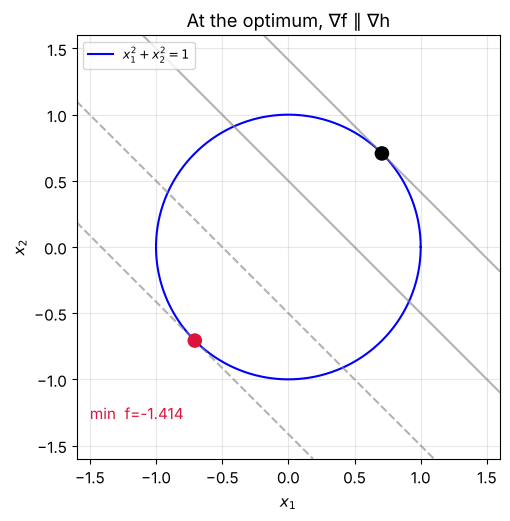

In [3]:
# @title Solve the circle example symbolically, then picture it
import sympy as sp, numpy as np, matplotlib.pyplot as plt
x1, x2, lam = sp.symbols("x1 x2 lambda", real=True)
L = (x1 + x2) + lam*(x1**2 + x2**2 - 1)
stat = sp.solve([sp.diff(L,x1), sp.diff(L,x2), sp.diff(L,lam)], [x1,x2,lam], dict=True)
for s in stat:
    f = float((x1+x2).subs(s))
    print(f"  x = ({float(s[x1]):+.3f}, {float(s[x2]):+.3f})"
          f"   lambda = {float(s[lam]):+.3f}   f = {f:+.3f}"
          f"   {'(min)' if f<0 else '(max)'}")

th = np.linspace(0, 2*np.pi, 300)
fig, ax = plt.subplots(figsize=(5.5,5.5))
ax.plot(np.cos(th), np.sin(th), 'b', label="$x_1^2+x_2^2=1$")
g1,g2 = np.meshgrid(np.linspace(-1.6,1.6,200), np.linspace(-1.6,1.6,200))
ax.contour(g1,g2,g1+g2, levels=[-1.414,-0.5,0.5,1.414], colors='gray', alpha=0.6)
ax.scatter([-0.707,0.707],[-0.707,0.707], c=['crimson','black'], s=90, zorder=5)
ax.annotate("min  f=-1.414",(-0.707,-0.707),(-1.5,-1.3),color='crimson')
ax.set_aspect('equal'); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title("At the optimum, ∇f ∥ ∇h"); ax.legend(loc='upper left', fontsize=9)
plt.show()

## 4. Second-order conditions

A stationary Lagrangian only flags *candidates*. To tell a minimum from a maximum we
look at curvature **along the constraint surface** — i.e. for feasible directions $y$
satisfying $\nabla h(x^\star)^\top y = 0$. Using the Lagrangian Hessian
$\nabla^2_x L = \nabla^2 f + \sum_i \lambda_i \nabla^2 h_i$:

- **Necessary:** $y^\top \nabla^2_x L\, y \ge 0$ for all such $y$ (positive
  semidefinite on the tangent space).
- **Sufficient:** $y^\top \nabla^2_x L\, y > 0$ (positive definite on the tangent
  space) — then $x^\star$ is a strict local minimum.

Applied to the circle, the curvature test confirms what the picture showed: one point
is a minimum, the other a maximum.


In [4]:
# @title Classify the two circle stationary points by tangent-space curvature
import numpy as np
# L = x1 + x2 + lam*(x1^2+x2^2-1) → ∇²_x L = 2*lam*I ; ∇h = 2*(x1,x2)
for (p, lam) in [((-0.7071,-0.7071), 0.7071), ((0.7071,0.7071), -0.7071)]:
    HL = 2*lam*np.eye(2)                       # Lagrangian Hessian
    gh = 2*np.array(p)                          # constraint gradient
    t  = np.array([-gh[1], gh[0]])              # a tangent direction (⊥ gh)
    curv = t @ HL @ t
    print(f"point {np.array(p).round(3)}  lam={lam:+.3f}  "
          f"tangent curvature = {curv:+.3f}  → "
          f"{'minimum' if curv>0 else 'maximum'}")

point [-0.707 -0.707]  lam=+0.707  tangent curvature = +5.657  → minimum
point [0.707 0.707]  lam=-0.707  tangent curvature = -5.657  → maximum


## 5. Inequality constraints and active sets

Now allow inequalities $g_j(x)\le 0$. The key new idea is **activity**. At a point
$x^\star$, constraint $g_j$ is:

- **active** if $g_j(x^\star) = 0$ (we are pressed against it), or
- **inactive** if $g_j(x^\star) < 0$ (we have room to spare).

Only **active** constraints can influence the optimum — an inactive one might as well
not be there. A vivid picture: a ball rolling downhill in a valley comes to rest either
at the valley floor (no constraint active) or **pinned against a fence** (a constraint
active), where the downhill pull $-\nabla f$ is exactly balanced by the fence's push
$\nabla g_j$. That force balance is what the KKT conditions make precise.


## 6. The Karush–Kuhn–Tucker (KKT) conditions

For the general NLP
$$\min f(x)\quad\text{s.t.}\quad h_i(x)=0,\ \ g_j(x)\le 0,$$
form the Lagrangian with multipliers $\lambda_i$ (equalities) and $\mu_j$
(inequalities):
$$L(x,\lambda,\mu) = f(x) + \sum_i \lambda_i h_i(x) + \sum_j \mu_j g_j(x).$$

A local optimum $x^\star$ (under a mild regularity assumption) satisfies the **KKT
conditions**:

| | Condition | Meaning |
|---|---|---|
| **Stationarity** | $\nabla f + \sum_i\lambda_i\nabla h_i + \sum_j\mu_j\nabla g_j = 0$ | force balance |
| **Primal feasibility** | $h_i = 0,\ \ g_j \le 0$ | satisfies the constraints |
| **Dual feasibility** | $\mu_j \ge 0$ | inequality pushes only "inward" |
| **Complementary slackness** | $\mu_j\, g_j = 0$ | $\mu_j = 0$ *or* $g_j = 0$ |

Complementary slackness is the algebraic form of "only active constraints matter": if a
constraint is slack ($g_j<0$) its multiplier is zero; a nonzero multiplier forces the
constraint active ($g_j=0$).

**Single-variable example.** $\min x^2$ s.t. $-a \le x \le a$ ($a>0$). By inspection
$x^\star = 0$. Both bounds are inactive, so both multipliers are zero and stationarity
gives $2x = 0$ — consistent. (Flip the objective to $\min -x^2$ and the optimum jumps to
the active bounds $x = \pm a$ with nonzero multipliers.)


In [5]:
# @title A reusable numerical KKT checker
import numpy as np

def kkt_report(grad_f, g_list, grad_g_list, x, mu, tol=1e-4):
    '''Check KKT for inequality-constrained min f s.t. g_j(x) <= 0.'''
    x = np.asarray(x, float); mu = np.asarray(mu, float)
    stat = grad_f(x) + sum(m*gg(x) for m, gg in zip(mu, grad_g_list))
    print("stationarity ‖∇f + Σμ∇g‖ =", np.linalg.norm(stat).round(6))
    for j,(g,m) in enumerate(zip(g_list, mu)):
        gv = g(x)
        print(f"  g{j+1}(x) = {gv:+.4f}  μ{j+1} = {m:+.4f}  "
              f"feasible={gv<=tol}  dual={m>=-tol}  "
              f"compl.(μg≈0)={abs(m*gv)<tol}")

# demo: min x^2 s.t. -a<=x<=a  (a=2)  → x*=0, μ=0
a = 2.0
kkt_report(grad_f=lambda x: np.array([2*x[0]]),
           g_list=[lambda x: x[0]-a, lambda x: -x[0]-a],
           grad_g_list=[lambda x: np.array([1.0]), lambda x: np.array([-1.0])],
           x=[0.0], mu=[0.0, 0.0])

stationarity ‖∇f + Σμ∇g‖ = 0.0
  g1(x) = -2.0000  μ1 = +0.0000  feasible=True  dual=True  compl.(μg≈0)=True
  g2(x) = -2.0000  μ2 = +0.0000  feasible=True  dual=True  compl.(μg≈0)=True


## 7. Multipliers as shadow prices; constraint qualification

The KKT multipliers are not bookkeeping — they carry economic meaning. For an active
constraint, relaxing its right-hand side by a small amount changes the optimal
objective at a rate equal to the multiplier:

$$\mu_j = -\frac{\partial f^\star}{\partial (\text{RHS of } g_j)}.$$

So multipliers are **shadow prices / dual variables** — exactly the sensitivity
information we met in LP duality (Module 2), now for nonlinear models.

One caveat: KKT is necessary for an optimum only when a **constraint qualification**
holds. A common one is **LICQ** (Linear Independence Constraint Qualification): the
gradients of the active constraints are linearly independent. Where it fails, a true
optimum can *violate* KKT. Classic failure: $\min x_1$ s.t. $x_2\ge 0,\ x_2\le x_1^3$.
The optimum is $(0,0)$, but the active-constraint gradients line up (dependent), so KKT
is not satisfied there — a reminder to check regularity, not just stationarity.


## 8. Convexity and a worked KKT example

When does satisfying KKT *guarantee* a global optimum? Convexity:

> If $f$ and every $g_j$ are **convex** and every $h_i$ is **linear** (so the feasible
> region is convex), then any KKT point is a **global** minimum — and the second-order
> conditions need not be checked.

This is why establishing convexity (Module 1) pays off: it upgrades KKT from *necessary*
to *sufficient and global*.

**Worked active-set example.**
$$\min\ \tfrac12(x_1^2+x_2^2) - 3x_1 - x_2 \quad\text{s.t.}\quad
-x_1+x_2\le 0,\ \ x_1-\tfrac12 x_2-2\le 0,\ \ -x_2\le 0.$$
The objective is a convex bowl; the constraints are linear, so any KKT point is global.
Guessing which constraints are active and solving the stationarity + activity equations
gives the optimum below.


In [6]:
# @title Solve the KKT example and verify every KKT condition
import numpy as np
from scipy.optimize import minimize

f  = lambda x: 0.5*(x[0]**2 + x[1]**2) - 3*x[0] - x[1]
gf = lambda x: np.array([x[0] - 3, x[1] - 1])            # ∇f
# g1=-x1+x2, g2=x1-0.5x2-2, g3=-x2  (all ≤ 0)
g_list      = [lambda x: -x[0]+x[1], lambda x: x[0]-0.5*x[1]-2, lambda x: -x[1]]
grad_g_list = [lambda x: np.array([-1.,1.]),
               lambda x: np.array([1.,-0.5]),
               lambda x: np.array([0.,-1.])]

res = minimize(f, [0,0],
               constraints=[{'type':'ineq','fun':lambda x,g=g:-g(x)} for g in g_list])
x = res.x
print(f"optimum x* = {x.round(3)},  f(x*) = {res.fun:.3f}")

# recover multipliers: only g2 is active → solve ∇f + μ2 ∇g2 = 0
mu2 = -(gf(x) @ grad_g_list[1](x)) / (grad_g_list[1](x) @ grad_g_list[1](x))
mu  = [0.0, mu2, 0.0]
print(f"active constraint: g2;  μ2 = {mu2:.3f}  (shadow price of its limit)")
kkt_report(gf, g_list, grad_g_list, x, mu)

optimum x* = [2.6 1.2],  f(x*) = -4.900
active constraint: g2;  μ2 = 0.400  (shadow price of its limit)
stationarity ‖∇f + Σμ∇g‖ = 0.0
  g1(x) = -1.4000  μ1 = +0.0000  feasible=True  dual=True  compl.(μg≈0)=True
  g2(x) = +0.0000  μ2 = +0.4000  feasible=True  dual=True  compl.(μg≈0)=True
  g3(x) = -1.2000  μ3 = +0.0000  feasible=True  dual=True  compl.(μg≈0)=True


## 9. KKT for a linear program — a bridge to duality

LP is just a convex NLP, so KKT applies and reproduces exactly the duality of Module 2.
Take $\max c^\top x$ s.t. $Ax \le b,\ x\ge 0$. Writing the KKT conditions with
multipliers $y$ on $Ax\le b$ yields:

- **stationarity** $\Rightarrow A^\top y \ge c$ (the dual constraints),
- **complementary slackness** $\Rightarrow$ $(b - Ax)_i\, y_i = 0$ and $x_j\,(A^\top y - c)_j = 0$,
- **dual feasibility** $\Rightarrow y \ge 0$.

Those are precisely the **dual LP** $\min b^\top y$ s.t. $A^\top y \ge c,\ y\ge 0$, with
the multipliers playing the role of shadow prices. KKT is the single framework
underneath both LP duality and nonlinear optimality.


## 10. Solving NLPs: SQP and interior-point methods

Real NLPs are solved by applying Newton's idea to the KKT system. Two families
dominate.

**Sequential Quadratic Programming (SQP).** At each iterate, approximate the problem by
a **quadratic program (QP)**: a quadratic model of the Lagrangian subject to *linearized*
constraints. Solving that QP gives a search direction; a line search ensures progress.
The Lagrangian Hessian is usually approximated by **BFGS**. SQP needs few iterations and
function evaluations — excellent for small-to-medium models with nonlinear constraints
(solver: SNOPT; `scipy`'s `SLSQP`).

**Interior-point / barrier methods.** Replace each inequality $g_j\le 0$ by a
logarithmic **barrier** added to the objective, controlled by a parameter $\mu\to 0$
that is driven to zero. Each subproblem is solved by Newton's method, tracing a *central
path* to the solution. These scale to very large models with many degrees of freedom
(solvers: IPOPT, KNITRO; `scipy`'s `trust-constr`).

A third family, **reduced-gradient** methods (CONOPT, MINOS, GRG in Excel), eliminates
variables using the constraints and optimizes in the remaining "superbasic" space.


In [7]:
# @title SQP (SLSQP) vs. interior-point (trust-constr) on a constrained NLP
import numpy as np
from scipy.optimize import minimize, NonlinearConstraint

# min 100(x^2 - y)^2 + (x-1)^2   s.t.   x^2 + y^2 <= 1.5
f = lambda v: 100*(v[0]**2 - v[1])**2 + (v[0]-1)**2
con = NonlinearConstraint(lambda v: v[0]**2 + v[1]**2, -np.inf, 1.5)

for method in ["SLSQP", "trust-constr"]:
    r = minimize(f, [-1, 1], method=method, constraints=[con])
    print(f"{method:13s} x* = {r.x.round(4)}  f = {r.fun:.5f}  iters = {r.nit}")

SLSQP         x* = [0.9072 0.8228]  f = 0.00862  iters = 32
trust-constr  x* = [0.9072 0.8227]  f = 0.00862  iters = 65


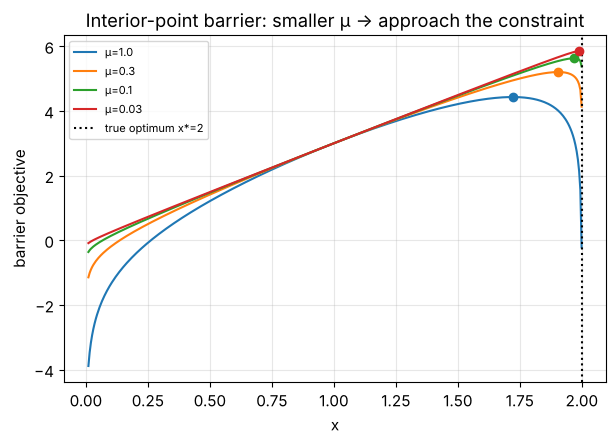

In [8]:
# @title The barrier idea in one picture: μ → 0 traces the optimum
import numpy as np, matplotlib.pyplot as plt
# max 3x s.t. x<=2, x>=0  ->  barrier: max 3x + μ[log(2-x)+log(x)]
mus = [1.0, 0.3, 0.1, 0.03]
x = np.linspace(0.01, 1.999, 400)
fig, ax = plt.subplots()
for mu in mus:
    ax.plot(x, 3*x + mu*(np.log(2-x)+np.log(x)), label=f"μ={mu}")
    xstar = 1 - mu/3 + np.sqrt(1 + mu**2/9)      # closed-form barrier maximizer
    ax.scatter(xstar, 3*xstar+mu*(np.log(2-xstar)+np.log(xstar)), zorder=5)
ax.axvline(2, color='k', ls=':', label="true optimum x*=2")
ax.set_xlabel("x"); ax.set_ylabel("barrier objective")
ax.set_title("Interior-point barrier: smaller μ → approach the constraint")
ax.legend(fontsize=8); plt.show()

## 11. Application: parameter estimation as an NLP

Fitting a nonlinear model to data is one of the most common NLPs in chemical
engineering — think Arrhenius kinetics, adsorption isotherms, or reactor models tuned to
plant data. Given measurements $(x_i, y_i)$ and a model $\hat y = m(x;\theta)$, we choose
parameters $\theta$ to minimize the sum of squared residuals:

$$\min_\theta \ \sum_i \big(m(x_i;\theta) - y_i\big)^2.$$

Unlike linear regression (Module 1), $m$ is nonlinear in $\theta$, so the objective can
be non-convex and is solved numerically. Here we recover the rate parameters of a
first-order process modeled as $y = a\,e^{b x}$.


estimated:  a = 3.209,  b = 0.769   (true: 3.0, 0.8)


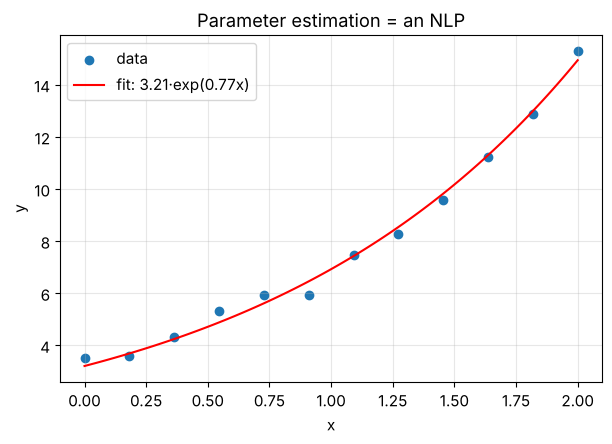

In [9]:
# @title Nonlinear least-squares fit of y = a·exp(b·x)
import numpy as np, matplotlib.pyplot as plt
from scipy.optimize import minimize

rng = np.random.RandomState(0)
xd  = np.linspace(0, 2, 12)
a_true, b_true = 3.0, 0.8
yd  = a_true*np.exp(b_true*xd) + rng.normal(0, 0.3, size=xd.size)

sse = lambda p: np.sum((p[0]*np.exp(p[1]*xd) - yd)**2)
res = minimize(sse, [1.0, 1.0], method="BFGS")
a_hat, b_hat = res.x
print(f"estimated:  a = {a_hat:.3f},  b = {b_hat:.3f}   (true: 3.0, 0.8)")

xs = np.linspace(0, 2, 100)
fig, ax = plt.subplots()
ax.scatter(xd, yd, label="data")
ax.plot(xs, a_hat*np.exp(b_hat*xs), 'r-', label=f"fit: {a_hat:.2f}·exp({b_hat:.2f}x)")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_title("Parameter estimation = an NLP")
ax.legend(); plt.show()

## 12. Non-convexity, local optima, and multistart

The hard truth of NLP: when the problem is **non-convex**, a solver returns a *local*
optimum, and which one depends on where you start. The gradient is zero at *every* local
optimum, so first-order methods cannot, on their own, tell a local from the global one.

A practical defense is **multistart**: launch a local solver from many starting points
and keep the best result. It is simple, parallelizable, and often effective — though it
offers no guarantee. (Rigorous **global optimization** is a later topic.) The plot below
shows a wiggly objective riddled with local minima, and multistart locating the deepest.


global-ish optimum: x* = [-0.491 -0.491],  f = -1.8458


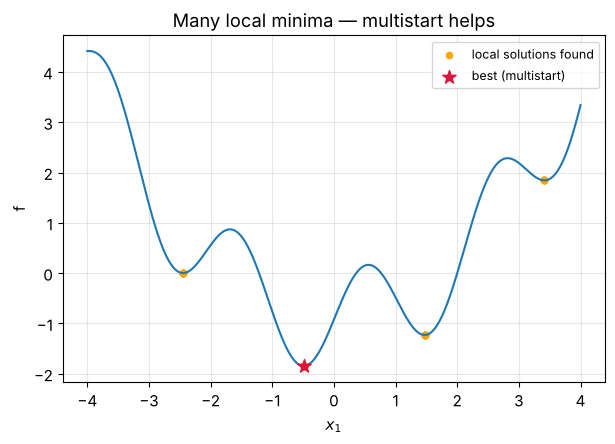

In [10]:
# @title Multistart on a non-convex objective
import numpy as np, matplotlib.pyplot as plt
from scipy.optimize import minimize

f = lambda x: np.sin(3*x[0]) + 0.3*x[0]**2 + np.sin(3*x[1]) + 0.3*x[1]**2

best, starts = None, []
for s in range(40):
    x0 = np.random.RandomState(s).uniform(-4, 4, 2)
    r  = minimize(f, x0)
    starts.append((r.x, r.fun))
    if best is None or r.fun < best.fun:
        best = r
print(f"global-ish optimum: x* = {best.x.round(3)},  f = {best.fun:.4f}")

# show the 1-D slice through x2=x*[1]
t = np.linspace(-4, 4, 500)
fig, ax = plt.subplots()
ax.plot(t, np.sin(3*t)+0.3*t**2 + np.sin(3*best.x[1])+0.3*best.x[1]**2)
locs = np.array([s[0][0] for s in starts])
ax.scatter(locs, [np.sin(3*c)+0.3*c**2+np.sin(3*best.x[1])+0.3*best.x[1]**2 for c in locs],
           color='orange', s=20, label="local solutions found")
ax.scatter(best.x[0], f(best.x), color='crimson', s=100, marker='*', zorder=5,
           label="best (multistart)")
ax.set_xlabel("$x_1$"); ax.set_ylabel("f"); ax.set_title("Many local minima — multistart helps")
ax.legend(fontsize=9); plt.show()

## 13. Modeling guidelines, solvers, and dynamic optimization

A few habits make NLPs converge far more reliably:

- **Bound every variable** ($x^L \le x \le x^U$) — it shrinks the search and guards
  against overflow.
- **Supply a good initial guess.** Non-convex solvers are only as good as their start.
- **Keep constraints linear where you can;** e.g. rewrite $x_1/x_2 \le 2$ (with
  $x_2>0$) as the linear $x_1 - 2x_2 \le 0$.
- **Scale** variables and constraints to comparable magnitudes.
- **Avoid undefined terms** — don't let a $\log$ or division hit zero at a candidate
  point; reformulate instead (e.g. replace $\ln z = w$ by $z = e^{w}$).

**Solver landscape.** SQP — SNOPT; reduced gradient — CONOPT, MINOS, Excel GRG;
interior-point — IPOPT, KNITRO. In Python, `scipy.optimize.minimize` offers `SLSQP`
(SQP) and `trust-constr` (interior-point-style); larger models are typically modeled in
Pyomo/GAMS and sent to IPOPT.

**Dynamic optimization** is where NLP meets differential equations: optimizing a process
*over time* subject to its dynamic model (DAEs) — optimal reactor temperature profiles,
batch recipes, trajectories. The standard trick is **direct transcription**: discretize
the ODEs (single/multiple shooting, or orthogonal collocation on finite elements) so the
infinite-dimensional problem becomes a large but ordinary NLP, then solve it with the
methods above. The tiny demo shows the idea.


In [11]:
# @title Direct transcription: a 1-D optimal-control problem becomes an NLP
import numpy as np
from scipy.optimize import minimize
# System  y' = -y + u ,  y(0)=1.  Drive y to 0 at t=T with least control effort.
# Discretize time into N steps (forward Euler); decision vars = controls u_0..u_{N-1}.
N, T = 20, 2.0
dt = T/N
def rollout(u):
    y = 1.0; ys=[y]
    for k in range(N):
        y = y + dt*(-y + u[k]); ys.append(y)
    return np.array(ys)
# objective: effort Σ u_k^2 dt  +  penalty on missing the target y(T)=0
obj = lambda u: np.sum(u**2)*dt + 50*rollout(u)[-1]**2
res = minimize(obj, np.zeros(N), method="SLSQP")
yT = rollout(res.x)[-1]
print(f"NLP with {N} control variables solved:")
print(f"  final state y(T) = {yT:.4f}  (target 0),  control effort = {np.sum(res.x**2)*dt:.4f}")

NLP with 20 control variables solved:
  final state y(T) = 0.0045  (target 0),  control effort = 0.0264


# Part 2 — Tutorial (Hands-on)

Attempt each **"Your turn"** cell before opening the solution.


## Exercise 1 — Newton's method, by hand then by solver

Minimize $f(x) = x^4 - 3x^2 + x$. Derive $f'$ and $f''$, implement one-dimensional
Newton from $x_0 = 2$, stop when $|f'| < 10^{-6}$, and confirm with `scipy`.


In [12]:
# @title Exercise 1 — Your turn
# f  = x^4 - 3x^2 + x ;  f' = 4x^3 - 6x + 1 ;  f'' = 12x^2 - 6
# TODO: x = 2.0 ; iterate x = x - f'(x)/f''(x) until |f'(x)| < 1e-6


In [13]:
# @title Exercise 1 — Solution
import numpy as np
from scipy.optimize import minimize
fp  = lambda x: 4*x**3 - 6*x + 1
fpp = lambda x: 12*x**2 - 6
x = 2.0
for k in range(1, 100):
    step = fp(x)/fpp(x); x -= step
    if abs(fp(x)) < 1e-6: break
print(f"Newton: x* = {x:.6f} in {k} iterations")
r = minimize(lambda v: v[0]**4 - 3*v[0]**2 + v[0], [2.0])
print(f"scipy : x* = {r.x[0]:.6f}")

Newton: x* = 1.130901 in 5 iterations
scipy : x* = 1.130902


## Exercise 2 — Lagrange multipliers

Minimize $f = x_1^2 + x_2^2$ subject to the equality $x_1 + x_2 = 4$. Solve the
first-order conditions by hand (set up the Lagrangian), then verify with `scipy`.


In [14]:
# @title Exercise 2 — Your turn
# L = x1^2 + x2^2 + lam*(x1 + x2 - 4)
# TODO: solve 2x1 + lam = 0, 2x2 + lam = 0, x1 + x2 = 4  (symbolically or by hand)


In [15]:
# @title Exercise 2 — Solution
import sympy as sp
from scipy.optimize import minimize
x1,x2,lam = sp.symbols("x1 x2 lam", real=True)
L = x1**2 + x2**2 + lam*(x1 + x2 - 4)
sol = sp.solve([sp.diff(L,x1), sp.diff(L,x2), sp.diff(L,lam)], [x1,x2,lam], dict=True)[0]
print("by hand :  x1 =", sol[x1], " x2 =", sol[x2], " lambda =", sol[lam])
r = minimize(lambda v: v[0]**2+v[1]**2, [0,0],
             constraints=[{'type':'eq','fun':lambda v: v[0]+v[1]-4}])
print("scipy   :  x* =", r.x.round(3), " f =", round(r.fun,3))

by hand :  x1 = 2  x2 = 2  lambda = -4
scipy   :  x* = [2. 2.]  f = 8.0


## Exercise 3 — Write and check the KKT conditions

For
$$\min\ x_1^2 + x_2^2 \quad\text{s.t.}\quad x_1^2 + x_2^2 \le 5,\ \ x_1 + 2x_2 = 4,\ \ x_1,x_2\ge 0,$$
state the KKT conditions, solve with `scipy`, and use the `kkt_report`-style logic to
confirm feasibility and which constraint is active.


In [16]:
# @title Exercise 3 — Your turn
from scipy.optimize import minimize
# objective x1^2+x2^2 ; inequality x1^2+x2^2-5<=0 ; equality x1+2x2-4=0 ; x>=0
# TODO: solve and inspect which constraints are active


In [17]:
# @title Exercise 3 — Solution
import numpy as np
from scipy.optimize import minimize
f = lambda v: v[0]**2 + v[1]**2
cons = [{'type':'ineq','fun':lambda v: 5 - (v[0]**2+v[1]**2)},   # x1^2+x2^2 <= 5
        {'type':'eq',  'fun':lambda v: v[0] + 2*v[1] - 4}]       # x1+2x2 = 4
r = minimize(f, [1,1], bounds=[(0,None),(0,None)], constraints=cons)
x = r.x
print(f"x* = {x.round(3)}  f = {r.fun:.3f}")
print(f"  inequality x1^2+x2^2 = {x[0]**2+x[1]**2:.3f} (≤5 → {'active' if abs(x[0]**2+x[1]**2-5)<1e-3 else 'inactive'})")
print(f"  equality   x1+2x2    = {x[0]+2*x[1]:.3f} (=4)")
print("  the equality alone pins the point; the disk constraint is slack.")

x* = [0.8 1.6]  f = 3.200
  inequality x1^2+x2^2 = 3.200 (≤5 → inactive)
  equality   x1+2x2    = 4.000 (=4)
  the equality alone pins the point; the disk constraint is slack.


## Exercise 4 — Determine a KKT point via active sets

$$\min\ x_1^2 + x_2^2 - 3x_1 - 4x_2 + 10 \quad\text{s.t.}\quad
x_1 - 2x_2 \le -1,\ \ x_1 + 2x_2 \le 4,\ \ x_1,x_2 \ge 0.$$

Find the optimum, identify the active constraint(s), recover the multiplier(s), and
argue (convex objective, linear constraints) that the KKT point is the **global**
optimum.


In [18]:
# @title Exercise 4 — Your turn
from scipy.optimize import minimize
# ∇f = [2x1-3, 2x2-4]. Try: which inequality is active at the optimum?
# TODO: solve with scipy, then recover the active multiplier from ∇f + μ ∇g = 0


In [19]:
# @title Exercise 4 — Solution
import numpy as np
from scipy.optimize import minimize
f  = lambda v: v[0]**2 + v[1]**2 - 3*v[0] - 4*v[1] + 10
gf = lambda v: np.array([2*v[0]-3, 2*v[1]-4])
g  = [lambda v: v[0]-2*v[1]+1, lambda v: v[0]+2*v[1]-4]          # ≤ 0
gg = [np.array([1.,-2.]), np.array([1.,2.])]
r  = minimize(f, [0,0], bounds=[(0,None),(0,None)],
              constraints=[{'type':'ineq','fun':lambda v,gi=gi:-gi(v)} for gi in g])
x = r.x
print(f"x* = {x.round(3)}  f = {r.fun:.3f}")
for j,gi in enumerate(g):
    print(f"  g{j+1}(x) = {gi(x):+.3f}  {'(active)' if abs(gi(x))<1e-3 else '(slack)'}")
# g2 active → μ2 from ∇f + μ2 ∇g2 = 0
mu2 = -(gf(x) @ gg[1])/(gg[1] @ gg[1])
print(f"  μ2 = {mu2:.3f}  (shadow price of the x1+2x2≤4 limit)")
print("  objective convex + constraints linear ⇒ KKT point is the GLOBAL optimum.")

x* = [1.2 1.4]  f = 4.200
  g1(x) = -0.600  (slack)
  g2(x) = +0.000  (active)
  μ2 = 0.600  (shadow price of the x1+2x2≤4 limit)
  objective convex + constraints linear ⇒ KKT point is the GLOBAL optimum.


## Exercise 5 — SQP on a constrained nonlinear problem

Solve
$$\min\ 100(x^2 - y)^2 + (x-1)^2 \quad\text{s.t.}\quad x^2 + y^2 \le 1.5$$
with `SLSQP` from two different starting points. Do they reach the same solution? What
does that tell you about the landscape?


In [20]:
# @title Exercise 5 — Your turn
from scipy.optimize import minimize, NonlinearConstraint
# f = 100(x^2-y)^2 + (x-1)^2 ; constraint x^2+y^2 <= 1.5
# TODO: minimize from [-1,1] and from [1,-1]; compare


In [21]:
# @title Exercise 5 — Solution
import numpy as np
from scipy.optimize import minimize, NonlinearConstraint
f = lambda v: 100*(v[0]**2-v[1])**2 + (v[0]-1)**2
con = NonlinearConstraint(lambda v: v[0]**2+v[1]**2, -np.inf, 1.5)
for x0 in [[-1,1],[1,-1]]:
    r = minimize(f, x0, method="SLSQP", constraints=[con])
    active = abs(r.x[0]**2+r.x[1]**2 - 1.5) < 1e-3
    print(f"start {x0}: x* = {r.x.round(3)}, f = {r.fun:.4f}, "
          f"constraint {'active' if active else 'slack'}")
print("Both reach the same optimum here — but on non-convex NLPs that is not guaranteed.")

start [-1, 1]: x* = [0.907 0.823], f = 0.0086, constraint active
start [1, -1]: x* = [0.907 0.823], f = 0.0086, constraint active
Both reach the same optimum here — but on non-convex NLPs that is not guaranteed.


## Exercise 6 — Multistart for a global optimum

The function $f(x) = x\sin(x) + 0.1x^2$ on $[-15, 15]$ has many local minima. Run a
local optimizer from 30 random starts and report the best solution found; plot the
function with the located minima.


In [22]:
# @title Exercise 6 — Your turn
import numpy as np
from scipy.optimize import minimize
# f = x*sin(x) + 0.1 x^2 ; 30 random starts in [-15,15]; keep the best


best: x* = 4.724, f = -2.492


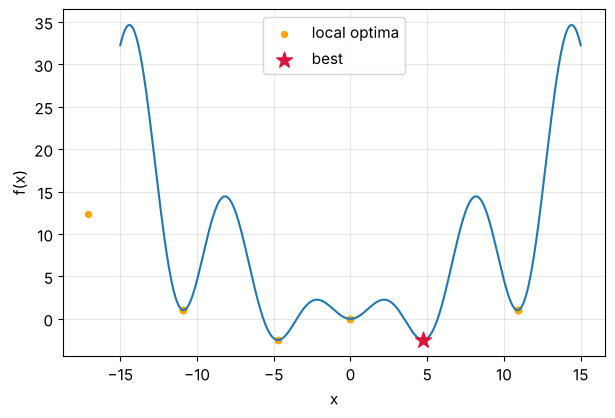

In [23]:
# @title Exercise 6 — Solution
import numpy as np, matplotlib.pyplot as plt
from scipy.optimize import minimize
f = lambda x: x[0]*np.sin(x[0]) + 0.1*x[0]**2
best = None; found = []
for s in range(30):
    x0 = np.random.RandomState(s).uniform(-15, 15, 1)
    r = minimize(f, x0); found.append(r.x[0])
    if best is None or r.fun < best.fun: best = r
print(f"best: x* = {best.x[0]:.3f}, f = {best.fun:.3f}")
t = np.linspace(-15, 15, 600)
fig, ax = plt.subplots()
ax.plot(t, t*np.sin(t)+0.1*t**2)
ax.scatter(found, [f([c]) for c in found], color='orange', s=18, label="local optima")
ax.scatter(best.x[0], best.fun, color='crimson', marker='*', s=140, zorder=5, label="best")
ax.set_xlabel("x"); ax.set_ylabel("f(x)"); ax.legend(); plt.show()

## Summary — key takeaways

- An **NLP** has a nonlinear objective and/or constraints. Unlike LP, the optimum can
  lie anywhere and there may be **many local optima**.
- **Unconstrained:** $\nabla f = 0$ with a positive-definite Hessian. **Newton** uses
  the Hessian (quadratic convergence); **BFGS** approximates it from gradients.
- **Equality constraints** are handled by the **Lagrangian** $L = f + \sum\lambda_i h_i$;
  first-order conditions make $\nabla f$ parallel to the constraint gradients.
- The **KKT conditions** — stationarity, primal/dual feasibility, and complementary
  slackness — generalize this to inequalities, with **active constraints** doing all the
  work. Multipliers are **shadow prices**, provided a **constraint qualification** holds.
- **Convexity** turns KKT from necessary into **sufficient and global**.
- Real NLPs are solved by **SQP** (Newton on the KKT system, QP subproblems — SNOPT,
  `SLSQP`), **interior-point/barrier** methods (IPOPT, KNITRO, `trust-constr`), or
  **reduced-gradient** methods (CONOPT, MINOS).
- **Parameter estimation** and **dynamic optimization** (via direct transcription) are
  NLPs at heart. For non-convex models, use **good initial guesses and multistart**, and
  follow the formulation guidelines to help solvers converge.

---

*Module 3 of CHE 581 — Process Optimization. Prepared by Abdulelah S. Alshehri,
Department of Chemical Engineering, King Saud University.*
